
# Student Stress Prediction: E0–E2 Reliability Experiments

This notebook establishes the methodological foundation for a reliability-centered student-stress prediction paper.

## Experiments
- **E0:** rigorous data audit.
- **E1A:** IID repeated stratified CV using all predictors.
- **E1B:** IID repeated stratified CV excluding `Student_Type`.
- **E2:** Leave-One-Student-Type-Out (LOSO), with `Student_Type` used only to define the unseen domain.

The primary transportability comparison is **E1B → E2** because both use the same predictor set.

> Associations in this benchmark dataset are predictive, not causal.


In [1]:

from pathlib import Path
import platform, json, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, brier_score_loss,
    log_loss, matthews_corrcoef, confusion_matrix
)

SEED = 42
TARGET = "Stress_Level"
GROUP = "Student_Type"
N_SPLITS = 5
N_REPEATS = 2

DATA_CANDIDATES = [
    Path("/mnt/data/student-lifestyle-and-stress-dataset.csv"),
    Path("../data/student-lifestyle-and-stress-dataset.csv"),
    Path("student-lifestyle-and-stress-dataset.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Set DATA_PATH to the CSV location.")

RESULT_DIR = Path("../outputs/E0_E2")
RESULT_DIR.mkdir(exist_ok=True)

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("sklearn:", sklearn.__version__)
print("Dataset:", DATA_PATH.resolve())


Python: 3.13.5
pandas: 2.2.3
sklearn: 1.8.0
Dataset: /mnt/data/student-lifestyle-and-stress-dataset.csv


In [2]:

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())


Shape: (25500, 9)


,Student_Type,Sleep_Hours,Study_Hours,Social_Media_Hours,Attendance,Exam_Pressure,Family_Support,Month,Stress_Level
0,school,6.868702,1.711722,3.176942,NaN,8.0,7.0,2.0,1
1,school,8.519088,3.251084,3.880787,93.978465,6.0,4.0,3.0,1
2,college,4.498770,6.306885,2.936172,64.421253,7.0,1.0,12.0,1
3,school,8.591223,2.384922,5.222832,81.868960,2.0,7.0,7.0,0
4,college,5.329293,9.345179,7.815869,85.847982,5.0,6.0,10.0,1


# E0 — Rigorous Data Audit

In [3]:

missing = pd.DataFrame({
    "missing_n": df.isna().sum(),
    "missing_pct": 100 * df.isna().mean(),
}).sort_values("missing_pct", ascending=False)

predictors = [c for c in df.columns if c != TARGET]
duplicates = pd.DataFrame({
    "check": [
        "extra_full_duplicate_rows",
        "extra_duplicate_predictor_rows",
        "conflicting_labels_for_duplicate_predictors",
    ],
    "count": [
        int(df.duplicated().sum()),
        int(df.duplicated(subset=predictors).sum()),
        int((df.groupby(predictors, dropna=False)[TARGET].nunique() > 1).sum()),
    ],
})

display(missing)
display(duplicates)
missing.to_csv(RESULT_DIR / "e0_missingness.csv")
duplicates.to_csv(RESULT_DIR / "e0_duplicates.csv", index=False)


,missing_n,missing_pct
Sleep_Hours,1333,5.227451
Month,1314,5.152941
Social_Media_Hours,1312,5.145098
Attendance,1305,5.117647
Family_Support,1291,5.062745
Study_Hours,1277,5.007843
Exam_Pressure,1270,4.980392
Student_Type,1252,4.909804
Stress_Level,0,0.000000


,check,count
0,extra_full_duplicate_rows,24
1,extra_duplicate_predictor_rows,24
2,conflicting_labels_for_duplicate_predictors,0


In [4]:

numeric_cols = df.select_dtypes(include=np.number).columns
ranges = pd.DataFrame({
    "min": df[numeric_cols].min(),
    "median": df[numeric_cols].median(),
    "mean": df[numeric_cols].mean(),
    "max": df[numeric_cols].max(),
    "missing_n": df[numeric_cols].isna().sum(),
    "unique_n": df[numeric_cols].nunique(),
})
display(ranges)
ranges.to_csv(RESULT_DIR / "e0_numeric_ranges.csv")

rules = {
    "Sleep_Hours_outside_0_24":
        df["Sleep_Hours"].notna() & ~df["Sleep_Hours"].between(0, 24),
    "Study_Hours_outside_0_24":
        df["Study_Hours"].notna() & ~df["Study_Hours"].between(0, 24),
    "Social_Media_Hours_outside_0_24":
        df["Social_Media_Hours"].notna() & ~df["Social_Media_Hours"].between(0, 24),
    "Attendance_outside_0_100":
        df["Attendance"].notna() & ~df["Attendance"].between(0, 100),
    "Exam_Pressure_outside_1_10":
        df["Exam_Pressure"].notna() & ~df["Exam_Pressure"].between(1, 10),
    "Family_Support_outside_1_10":
        df["Family_Support"].notna() & ~df["Family_Support"].between(1, 10),
    "Month_outside_1_12":
        df["Month"].notna() & ~df["Month"].between(1, 12),
}

validity = pd.DataFrame([
    {"rule": name, "invalid_n": int(mask.sum()), "invalid_pct": 100 * mask.mean()}
    for name, mask in rules.items()
])
display(validity)
validity.to_csv(RESULT_DIR / "e0_validity_flags.csv", index=False)


,min,median,mean,max,missing_n,unique_n
Sleep_Hours,2.008586,6.542566,6.458948,9.997527,1333,23695
Study_Hours,-1.433434,4.538138,4.696477,22.444460,1277,24223
Social_Media_Hours,0.000040,3.500709,3.555614,9.962134,1312,23713
Attendance,-5.000000,81.942959,81.270961,120.000000,1305,23576
Exam_Pressure,1.000000,5.000000,5.369748,10.000000,1270,10
Family_Support,1.000000,6.000000,5.798298,10.000000,1291,10
Month,1.000000,6.000000,6.500992,12.000000,1314,12
Stress_Level,0.000000,0.000000,0.299882,1.000000,0,2


,rule,invalid_n,invalid_pct
0,Sleep_Hours_outside_0_24,0,0.000000
1,Study_Hours_outside_0_24,21,0.082353
2,Social_Media_Hours_outside_0_24,0,0.000000
3,Attendance_outside_0_100,112,0.439216
4,Exam_Pressure_outside_1_10,0,0.000000
5,Family_Support_outside_1_10,0,0.000000
6,Month_outside_1_12,0,0.000000


,Student_Type_Audit,n,high_stress_n,high_stress_rate,high_stress_pct
0,MISSING,1252,382,0.305112,30.511182
1,college,13391,4185,0.312523,31.252334
2,school,6021,1233,0.204783,20.478326
3,working_student,4836,1847,0.381927,38.192721


,Month,n,high_stress_n,high_stress_rate,high_stress_pct
0,1.0,1989,638,0.320764,32.076420
1,2.0,2027,681,0.335964,33.596448
2,3.0,2063,722,0.349976,34.997576
3,4.0,1987,682,0.343231,34.323100
4,5.0,2044,655,0.320450,32.045010
5,6.0,1992,566,0.284137,28.413655
6,7.0,2018,549,0.272052,27.205154
7,8.0,2023,527,0.260504,26.050420
8,9.0,1967,496,0.252161,25.216065
9,10.0,2019,524,0.259534,25.953442


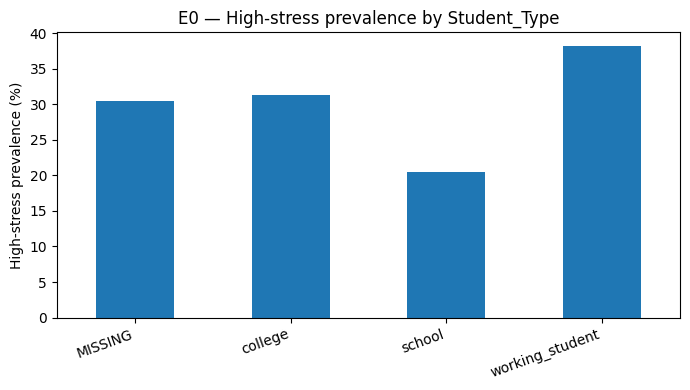

In [5]:

student_prev = (
    df.assign(Student_Type_Audit=df[GROUP].fillna("MISSING"))
      .groupby("Student_Type_Audit")[TARGET]
      .agg(n="size", high_stress_n="sum", high_stress_rate="mean")
      .reset_index()
)
student_prev["high_stress_pct"] = 100 * student_prev["high_stress_rate"]

month_prev = (
    df.groupby("Month", dropna=False)[TARGET]
      .agg(n="size", high_stress_n="sum", high_stress_rate="mean")
      .reset_index()
)
month_prev["high_stress_pct"] = 100 * month_prev["high_stress_rate"]

display(student_prev)
display(month_prev)

student_prev.to_csv(RESULT_DIR / "e0_prevalence_by_student_type.csv", index=False)
month_prev.to_csv(RESULT_DIR / "e0_prevalence_by_month.csv", index=False)

ax = student_prev.set_index("Student_Type_Audit")["high_stress_pct"].plot(
    kind="bar", figsize=(7, 4)
)
ax.set_ylabel("High-stress prevalence (%)")
ax.set_xlabel("")
ax.set_title("E0 — High-stress prevalence by Student_Type")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(RESULT_DIR / "fig_e0_prevalence_student_type.png", dpi=200, bbox_inches="tight")
plt.show()


In [6]:

signal_cols = [
    "Sleep_Hours", "Study_Hours", "Social_Media_Hours",
    "Attendance", "Exam_Pressure", "Family_Support", "Month"
]
signal_rows = []
for col in signal_cols:
    tmp = df[[col, TARGET]].dropna()
    corr = tmp[col].corr(tmp[TARGET])
    signal_rows.append({
        "feature": col,
        "n_complete": len(tmp),
        "point_biserial_corr": corr,
        "abs_corr": abs(corr),
    })

signal_audit = (
    pd.DataFrame(signal_rows)
      .sort_values("abs_corr", ascending=False)
)
display(signal_audit)
signal_audit.to_csv(RESULT_DIR / "e0_numeric_signal_audit.csv", index=False)


,feature,n_complete,point_biserial_corr,abs_corr
4,Exam_Pressure,24230,0.519061,0.519061
1,Study_Hours,24223,0.215776,0.215776
0,Sleep_Hours,24167,-0.145736,0.145736
5,Family_Support,24209,-0.107542,0.107542
2,Social_Media_Hours,24188,0.089968,0.089968
6,Month,24186,-0.049948,0.049948
3,Attendance,24195,-0.032811,0.032811



# Leakage-safe baseline pipeline

For E0–E2 we intentionally use **Logistic Regression as the primary model**.  
The immediate question is whether the validation protocol exposes population-shift risk; model-complexity comparisons are deferred.

- Numeric: median imputation + standardization.
- Categorical: most-frequent imputation + one-hot encoding.
- `Month` is categorical.
- Threshold-dependent metrics use 0.50 only as an initial diagnostic.


In [7]:

NUMERIC_FEATURES = [
    "Sleep_Hours", "Study_Hours", "Social_Media_Hours",
    "Attendance", "Exam_Pressure", "Family_Support"
]
ALL_FEATURES = NUMERIC_FEATURES + ["Student_Type", "Month"]
GROUPBLIND_FEATURES = NUMERIC_FEATURES + ["Month"]

def make_lr_pipeline(categorical_cols):
    prep = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), NUMERIC_FEATURES),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical_cols),
    ], sparse_threshold=0)

    return Pipeline([
        ("prep", prep),
        ("model", LogisticRegression(
            max_iter=2000,
            solver="lbfgs",
            random_state=SEED,
        )),
    ])

def classification_metrics(y_true, prob, threshold=0.50):
    y_true = np.asarray(y_true).astype(int)
    prob = np.asarray(prob, dtype=float)
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()

    return {
        "accuracy": accuracy_score(y_true, pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "specificity": tn / (tn + fp),
        "f1": f1_score(y_true, pred, zero_division=0),
        "mcc": matthews_corrcoef(y_true, pred),
        "roc_auc": roc_auc_score(y_true, prob),
        "pr_auc": average_precision_score(y_true, prob),
        "brier": brier_score_loss(y_true, prob),
        "nll": log_loss(y_true, prob, labels=[0, 1]),
    }

METRICS = [
    "accuracy", "balanced_accuracy", "precision", "recall",
    "specificity", "f1", "mcc", "roc_auc", "pr_auc", "brier", "nll"
]


# E1 — Reproducible IID Baseline

In [8]:

def run_iid(features, categorical_cols, feature_set_name):
    X = df[features].copy()
    y = df[TARGET].astype(int).copy()

    cv = RepeatedStratifiedKFold(
        n_splits=N_SPLITS,
        n_repeats=N_REPEATS,
        random_state=SEED,
    )

    rows = []
    for split_id, (tr, te) in enumerate(cv.split(X, y), start=1):
        model = make_lr_pipeline(categorical_cols)
        model.fit(X.iloc[tr], y.iloc[tr])
        prob = model.predict_proba(X.iloc[te])[:, 1]

        rows.append({
            "feature_set": feature_set_name,
            "repeat": (split_id - 1) // N_SPLITS + 1,
            "fold": (split_id - 1) % N_SPLITS + 1,
            "n_train": len(tr),
            "n_test": len(te),
            **classification_metrics(y.iloc[te], prob),
        })
    return pd.DataFrame(rows)

e1a = run_iid(ALL_FEATURES, ["Student_Type", "Month"], "E1A_ALL")
e1b = run_iid(GROUPBLIND_FEATURES, ["Month"], "E1B_GROUPBLIND")
e1 = pd.concat([e1a, e1b], ignore_index=True)

e1_summary = e1.groupby("feature_set")[METRICS].agg(["mean", "std"])
display(e1_summary)
e1.to_csv(RESULT_DIR / "e1_fold_metrics.csv", index=False)
e1_summary.to_csv(RESULT_DIR / "e1_summary_mean_sd.csv")


accuracy            ...       nll          
                    mean       std  ...      mean       std
feature_set                         ...                    
E1A_ALL         0.816059  0.002966  ...  0.408820  0.004776
E1B_GROUPBLIND  0.816294  0.002496  ...  0.408739  0.004733

[2 rows x 22 columns]

## E1B subgroup OOF diagnostic

In [9]:

X = df[GROUPBLIND_FEATURES].copy()
y = df[TARGET].astype(int).copy()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof_prob = np.full(len(df), np.nan)

for tr, te in cv.split(X, y):
    model = make_lr_pipeline(["Month"])
    model.fit(X.iloc[tr], y.iloc[tr])
    oof_prob[te] = model.predict_proba(X.iloc[te])[:, 1]

oof = pd.DataFrame({
    "y_true": y.values,
    "prob": oof_prob,
    "Student_Type": df[GROUP].fillna("MISSING").values,
})

subgroup_rows = []
for grp, part in oof.groupby("Student_Type"):
    subgroup_rows.append({
        "Student_Type": grp,
        "n": len(part),
        "prevalence": part["y_true"].mean(),
        **classification_metrics(part["y_true"], part["prob"]),
    })

e1_subgroup = pd.DataFrame(subgroup_rows)
display(e1_subgroup[
    ["Student_Type", "n", "prevalence", "roc_auc", "pr_auc",
     "recall", "specificity", "brier", "nll"]
])
e1_subgroup.to_csv(
    RESULT_DIR / "e1b_lr_oof_subgroup_metrics.csv", index=False
)


,Student_Type,n,prevalence,roc_auc,pr_auc,recall,specificity,brier,nll
0,MISSING,1252,0.305112,0.876271,0.756185,0.638743,0.904598,0.125698,0.399842
1,college,13391,0.312523,0.862319,0.752237,0.614576,0.898544,0.134040,0.420333
2,school,6021,0.204783,0.856507,0.650835,0.480941,0.943609,0.109148,0.354335
3,working_student,4836,0.381927,0.860517,0.805152,0.687060,0.857812,0.144772,0.446948



# E2 — Leave-One-Student-Type-Out

`Student_Type` is excluded from predictors and used only to define the unseen domain.  
Rows with missing `Student_Type` are excluded because their domain membership is undefined.


In [10]:

e2_df = df[df[GROUP].notna()].copy()
groups = sorted(e2_df[GROUP].unique())

rows = []
for heldout in groups:
    train_mask = e2_df[GROUP] != heldout
    test_mask = e2_df[GROUP] == heldout

    X_train = e2_df.loc[train_mask, GROUPBLIND_FEATURES]
    y_train = e2_df.loc[train_mask, TARGET].astype(int)
    X_test = e2_df.loc[test_mask, GROUPBLIND_FEATURES]
    y_test = e2_df.loc[test_mask, TARGET].astype(int)

    model = make_lr_pipeline(["Month"])
    model.fit(X_train, y_train)
    prob = model.predict_proba(X_test)[:, 1]

    rows.append({
        "heldout_group": heldout,
        "n_train": len(X_train),
        "n_test": len(X_test),
        "train_prevalence": y_train.mean(),
        "test_prevalence": y_test.mean(),
        **classification_metrics(y_test, prob),
    })

e2 = pd.DataFrame(rows)
display(e2[
    ["heldout_group", "n_test", "test_prevalence",
     "roc_auc", "pr_auc", "recall", "specificity", "brier", "nll"]
])
e2.to_csv(RESULT_DIR / "e2_loso_metrics.csv", index=False)


,heldout_group,n_test,test_prevalence,roc_auc,pr_auc,recall,specificity,brier,nll
0,college,13391,0.312523,0.861839,0.750966,0.608841,0.899196,0.134279,0.421118
1,school,6021,0.204783,0.854663,0.646031,0.477697,0.942147,0.109888,0.356406
2,working_student,4836,0.381927,0.859801,0.804854,0.687060,0.860154,0.145100,0.447814


In [11]:

weights = e2["n_test"] / e2["n_test"].sum()

higher = [
    "accuracy", "balanced_accuracy", "precision", "recall",
    "specificity", "f1", "mcc", "roc_auc", "pr_auc"
]
lower = ["brier", "nll"]

iid_mean = e1b[METRICS].mean()
shift_rows = []

for metric in METRICS:
    loso_weighted = np.sum(e2[metric] * weights)
    loso_worst = e2[metric].min() if metric in higher else e2[metric].max()

    weighted_worsening = (
        iid_mean[metric] - loso_weighted
        if metric in higher
        else loso_weighted - iid_mean[metric]
    )
    worst_worsening = (
        iid_mean[metric] - loso_worst
        if metric in higher
        else loso_worst - iid_mean[metric]
    )

    shift_rows.append({
        "metric": metric,
        "iid_groupblind_mean": iid_mean[metric],
        "loso_weighted": loso_weighted,
        "loso_worst_group": loso_worst,
        "weighted_worsening": weighted_worsening,
        "worst_group_worsening": worst_worsening,
    })

shift_penalty = pd.DataFrame(shift_rows)
display(shift_penalty[
    shift_penalty["metric"].isin(
        ["roc_auc", "pr_auc", "recall", "specificity", "brier", "nll"]
    )
])
shift_penalty.to_csv(
    RESULT_DIR / "e1b_to_e2_shift_penalty.csv", index=False
)


,metric,iid_groupblind_mean,loso_weighted,loso_worst_group,weighted_worsening,worst_group_worsening
3,recall,0.611025,0.591877,0.477697,0.019148,0.133328
4,specificity,0.904218,0.902075,0.860154,0.002143,0.044064
7,roc_auc,0.865711,0.859650,0.854663,0.006061,0.011049
8,pr_auc,0.751886,0.735657,0.646031,0.016229,0.105854
9,brier,0.129771,0.130380,0.145100,0.000609,0.015329
10,nll,0.408739,0.410374,0.447814,0.001635,0.039075


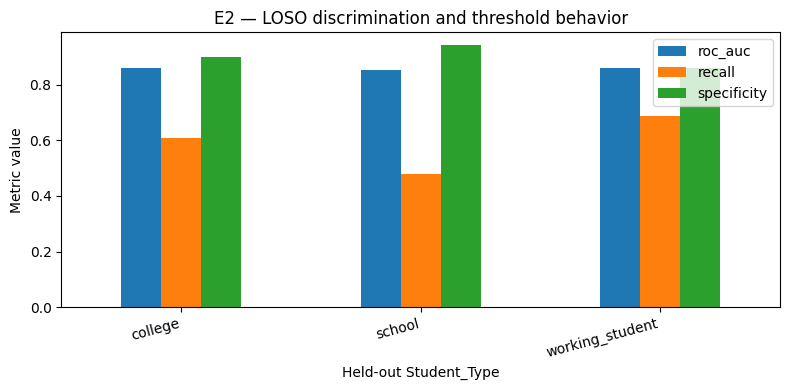

In [12]:

ax = e2.set_index("heldout_group")[["roc_auc", "recall", "specificity"]].plot(
    kind="bar", figsize=(8, 4)
)
ax.set_ylabel("Metric value")
ax.set_xlabel("Held-out Student_Type")
ax.set_title("E2 — LOSO discrimination and threshold behavior")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(RESULT_DIR / "fig_e2_loso_core_metrics.png", dpi=200, bbox_inches="tight")
plt.show()



# Decision Gate for the Next Experiments

Proceed to calibration-under-shift, GroupDRO, and conformal prediction when at least one of the following is observed:

1. LOSO is worse than E1B IID.
2. Worst-group performance is substantially below weighted-average performance.
3. ROC-AUC remains similar while recall/specificity varies materially across populations.
4. Brier/NLL deteriorate under held-out-domain evaluation.

A small AUC drop **does not invalidate** the hypothesis if operational or probabilistic reliability differs by population.


In [13]:

manifest = {
    "dataset_rows": len(df),
    "dataset_columns": df.shape[1],
    "seed": SEED,
    "iid_protocol": f"RepeatedStratifiedKFold({N_SPLITS} folds x {N_REPEATS} repeats)",
    "primary_model": "LogisticRegression",
    "e1a_features": ALL_FEATURES,
    "e1b_e2_features": GROUPBLIND_FEATURES,
    "e2_missing_group_rows_excluded": int(df[GROUP].isna().sum()),
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "sklearn": sklearn.__version__,
}
with open(RESULT_DIR / "run_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print("Saved files:")
for p in sorted(RESULT_DIR.glob("*")):
    print("-", p)


Saved files:
- student_stress_e0_e2_outputs/e0_duplicates.csv
- student_stress_e0_e2_outputs/e0_missingness.csv
- student_stress_e0_e2_outputs/e0_numeric_ranges.csv
- student_stress_e0_e2_outputs/e0_numeric_signal_audit.csv
- student_stress_e0_e2_outputs/e0_prevalence_by_month.csv
- student_stress_e0_e2_outputs/e0_prevalence_by_student_type.csv
- student_stress_e0_e2_outputs/e0_target_distribution.csv
- student_stress_e0_e2_outputs/e0_validity_flags.csv
- student_stress_e0_e2_outputs/e1_fold_metrics.csv
- student_stress_e0_e2_outputs/e1_lr_groupblind_oof_subgroup_metrics.csv
- student_stress_e0_e2_outputs/e1_primary_mean_metrics.csv
- student_stress_e0_e2_outputs/e1_summary_mean_sd.csv
- student_stress_e0_e2_outputs/e1b_lr_oof_subgroup_metrics.csv
- student_stress_e0_e2_outputs/e1b_to_e2_shift_penalty.csv
- student_stress_e0_e2_outputs/e2_loso_metrics.csv
- student_stress_e0_e2_outputs/e2_weighted_and_worst_group.csv
- student_stress_e0_e2_outputs/fig_e0_missingness.png
- student_stres